# Podstawy AI – Logika rozmyta

**Jedna myśl na całe zajęcia:** ostra granica jest krucha – zmiękczamy ją do stopni. A potem każdy krok, który wydaje się „matematyczny”, okazuje się **decyzją projektową**.


**Jak pracujemy:**
- **TODO** w kodzie – tu piszesz kod. Wzory są w prezentacji.
- **Testy** – komórka, którą uruchamiasz bez zmian. Wypisze `OK` albo `BŁĄD` z przypadkiem, który nie działa.
- **Pytanie** – odpowiadasz 2–3 zdaniami w komórce „Twoja odpowiedź” pod spodem.

Oddajesz ten notebook.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from functools import reduce


def sprawdz(nazwa, f, przypadki):
    """Testuje funkcję f: przypadki = lista (argumenty, oczekiwany_wynik)."""
    bledy = 0
    for args, oczekiwane in przypadki:
        try:
            wynik = f(*args)
            ok = wynik is not None and np.allclose(np.asarray(wynik, float), oczekiwane, atol=1e-6)
        except Exception as e:
            wynik, ok = f"BŁĄD: {e}", False
        if not ok:
            bledy += 1
            arg = ", ".join(str(np.round(a, 3).tolist()) if isinstance(a, np.ndarray) else str(a) for a in args)
            print(f"BŁĄD  {nazwa}({arg}) = {wynik}, oczekiwano {oczekiwane}")
    print(f"OK    {nazwa}" if bledy == 0 else f"      {nazwa}: {bledy} błędnych przypadków")

---
## Część 1. Funkcje przynależności

### 1.1 Ostra granica vs stopień przynależności

Klasycznie: „wysoka temperatura” to np. **powyżej 25 °C**. Albo tak, albo nie. Rozmyta wersja używa funkcji **γ** z wykładu. Oto jej implementacja – wzoruj się na niej w zadaniu 1.2.

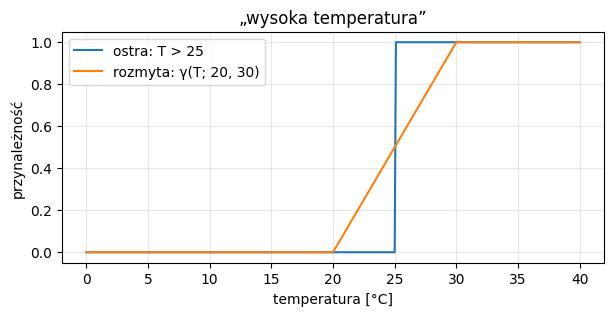

T = 24.9:  ostra = 0,  rozmyta = 0.49
T = 25.1:  ostra = 1,  rozmyta = 0.51


In [4]:
def gamma(x, a, b):
    """Funkcja γ: 0 dla x <= a, liniowo rośnie, 1 dla x >= b. Np. 'wysoki', 'duży'."""
    x = np.asarray(x, dtype=float)
    return np.clip((x - a) / (b - a), 0, 1)


x = np.linspace(0, 40, 401)
plt.figure(figsize=(7, 3))
plt.plot(x, (x > 25).astype(float), label="ostra: T > 25")
plt.plot(x, gamma(x, 20, 30), label="rozmyta: γ(T; 20, 30)")
plt.xlabel("temperatura [°C]"); plt.ylabel("przynależność"); plt.legend(); plt.grid(alpha=.3)
plt.title("„wysoka temperatura”"); plt.show()

for T in (24.9, 25.1):
    print(f"T = {T}:  ostra = {float(T > 25):.0f},  rozmyta = {float(gamma(T, 20, 30)):.2f}")

**Pytanie 1a.** 24,9 °C i 25,1 °C różnią się o 0,2 stopnia. Co z tą różnicą robi definicja ostra, a co rozmyta? Która jest bliższa temu, jak mówią ludzie?

*Twoja odpowiedź:*

Bliższa rzeczywistości jest funkcja rozmyta, ponieważ odczuwalność temperatury jest stopniowa, a nie tak jak w przypadku funkcji ostrej "zero-jedynkowa". Definicja przynależności jest bliższa naszej rzeczywistości.

### 1.2 Funkcje L i trójkątna

Zaimplementuj dwie funkcje z wykładu:
- **L(x; a, b)** – 1 dla x ≤ a, liniowo maleje, 0 dla x ≥ b (np. „niski”, „mały”),
- **t(x; a, b, c)** – trójkąt: 0 dla x ≤ a, rośnie do 1 w punkcie b, maleje do 0 w c (np. „średni”).

Funkcje muszą działać zarówno dla pojedynczej liczby, jak i dla całej tablicy `np.array`. Podpowiedź: zobacz, jak zbudowana jest `gamma`. Przydadzą się `np.clip` i `np.minimum`.

In [5]:
def L(x, a, b):
    x = np.asarray(x, dtype=float)
    # TODO

    return np.clip((b - x) / (b - a), 0, 1)

    return np.zeros_like(x)


def t(x, a, b, c):
    x = np.asarray(x, dtype=float)
    # TODO

    return np.clip(np.minimum((x - a) / (b - a), (c - x) / (c - b)), 0, 1)

    return np.zeros_like(x)

OK    L
OK    t


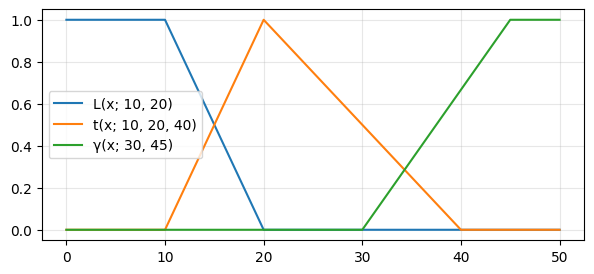

In [6]:
# Testy – uruchom bez zmian
sprawdz("L", L, [((0, 10, 20), 1), ((10, 10, 20), 1), ((15, 10, 20), 0.5), ((20, 10, 20), 0), ((30, 10, 20), 0),
                 ((np.array([5, 12.5, 25]), 10, 20), [1, 0.75, 0])])
sprawdz("t", t, [((0, 10, 20, 40), 0), ((15, 10, 20, 40), 0.5), ((20, 10, 20, 40), 1), ((30, 10, 20, 40), 0.5),
                 ((40, 10, 20, 40), 0), ((50, 10, 20, 40), 0), ((np.array([10, 20, 35]), 10, 20, 40), [0, 1, 0.25])])

xx = np.linspace(0, 50, 501)
plt.figure(figsize=(7, 3))
plt.plot(xx, L(xx, 10, 20), label="L(x; 10, 20)")
plt.plot(xx, t(xx, 10, 20, 40), label="t(x; 10, 20, 40)")
plt.plot(xx, gamma(xx, 30, 45), label="γ(x; 30, 45)")
plt.legend(); plt.grid(alpha=.3); plt.show()

### 1.3 Prędkość samochodu

Zdefiniuj cztery zbiory na przedziale 0–200 km/h: **mała**, **średnia**, **duża**, **bardzo duża**. Użyj swoich `L`, `t` i `gamma`. Poniższe liczby są celowo złe – popraw je.

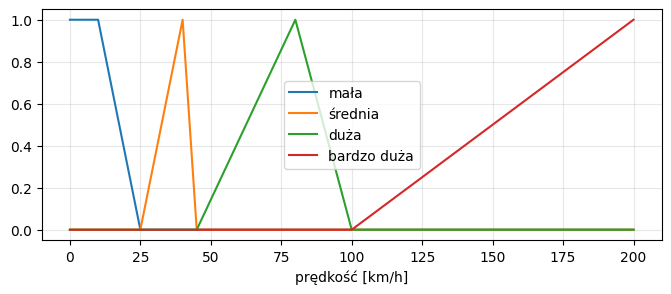

In [7]:
v = np.linspace(0, 200, 401)

# TODO: popraw parametry
mala        = L(v, 10, 25)
srednia     = t(v, 25, 40, 45)
duza        = t(v, 45, 80, 100)
bardzo_duza = gamma(v, 100, 200)

plt.figure(figsize=(8, 3))
for y, n in [(mala, "mała"), (srednia, "średnia"), (duza, "duża"), (bardzo_duza, "bardzo duża")]:
    plt.plot(v, y, label=n)
plt.xlabel("prędkość [km/h]"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Pytanie 1b.** Dlaczego wybrałeś takie liczby? Czy „duża prędkość” w mieście i na autostradzie to ten sam zbiór?

**Pytanie 1c.** Porównaj swój wykres z osobą obok. Jeśli się różnią – kto ma rację?

*Twoja odpowiedź:*

Po porównaniu wartości wynika, że odczycie "małej" i "dużej" prędkości jest subiektywne. Co prawda mała prędkość w mieście jest zdecydowanie za mała na autostradzie. Wartość prędkości zależy od badanego kontekstu. Średnia tych pomiarów jest określona w przepisach prawa drogowego, co ułatwia obiektywnie określić, czy dana prędkość jest "mała" czy "duża".

### 1.4 „Bardzo” i „trochę” (koncentracja i rozcieńczenie)

Zaimplementuj dwie operacje z wykładu: **CON** („bardzo”) i **DIL** („trochę”). Każda to jedna linijka.

In [8]:
def CON(bardzo):
    # TODO
    return bardzo**2


def DIL(troche):
    # TODO
    return np.sqrt(np.asarray(troche, float))

OK    CON
OK    DIL


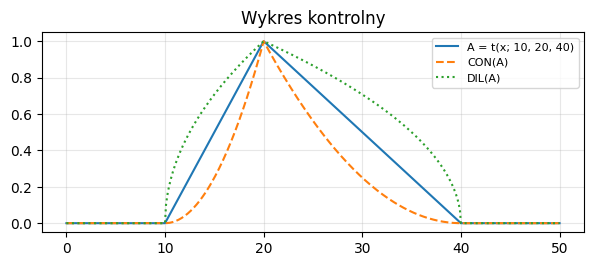

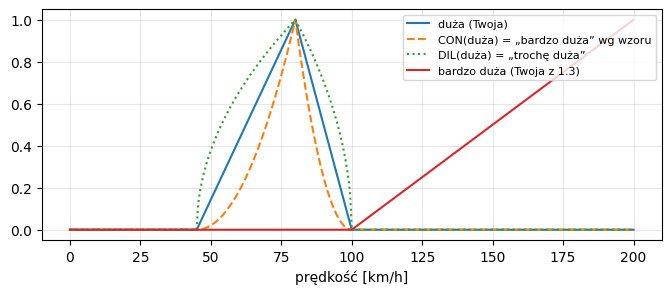

In [9]:
# Testy
sprawdz("CON", CON, [((0.5,), 0.25), ((1.0,), 1.0), ((np.array([0, 0.3, 0.9]),), [0, 0.09, 0.81])])
sprawdz("DIL", DIL, [((0.25,), 0.5), ((1.0,), 1.0), ((np.array([0, 0.49, 0.81]),), [0, 0.7, 0.9])])

# Wykres kontrolny – porównaj z prezentacją
xx = np.linspace(0, 50, 501)
A_ = t(xx, 10, 20, 40)
plt.figure(figsize=(7, 2.6))
plt.plot(xx, A_, label="A = t(x; 10, 20, 40)")
plt.plot(xx, CON(A_), "--", label="CON(A)")
plt.plot(xx, DIL(A_), ":", label="DIL(A)")
plt.title("Wykres kontrolny"); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()

plt.figure(figsize=(8, 3))
plt.plot(v, duza, label="duża (Twoja)")
plt.plot(v, CON(duza), "--", label="CON(duża) = „bardzo duża” wg wzoru")
plt.plot(v, DIL(duza), ":", label="DIL(duża) = „trochę duża”")
plt.plot(v, bardzo_duza, label="bardzo duża (Twoja z 1.3)")
plt.xlabel("prędkość [km/h]"); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()

**Pytanie 1d.** Porównaj CON(duża) z Twoim zbiorem „bardzo duża”. Czym się różnią kształtem i położeniem? Które lepiej oddaje, co ludzie mają na myśli, mówiąc „bardzo szybko”?

*Twoja odpowiedź:*

Zbiór "bardzo duża" na wykresie lepiej oddaje zjawisko zmiany prędkości, ponieważ w rzeczywistości nie jesteśmy w stanie liniowo zwiększać prędkości samochodu, a "CON(duża)" pokazuje na wykresie stopniowe wzrosty. Na moim wykresie zmiana prędkości pokazana jest liniowo, co nie zawsze ma praktyczne zastosowanie w rzeczywistości.

---
## Część 2. Operacje na zbiorach rozmytych

W logice klasycznej „i” to część wspólna, „lub” to suma, „nie” to dopełnienie – i są **jednoznaczne**. W logice rozmytej „i” to dowolna **t-norma**, „lub” to **s-norma**, i jest ich wiele.

### 2.1 Implementacja operatorów

Zaimplementuj operatory z wykładu. Wszystkie działają element po elemencie na tablicach (`np.minimum`, `np.maximum`, `np.where` …).

| | „i” (t-norma) | „lub” (s-norma) |
|---|---|---|
| Zadeha | minimum | maksimum |
| algebraiczne | iloczyn | suma probabilistyczna |
| Łukasiewicza | iloczyn ograniczony | suma ograniczona |
| drastyczne | iloczyn drastyczny | suma drastyczna |

oraz negację (dopełnienie).

In [10]:
def NIE(a):
    # TODO
    return 1 - a

# t-normy ("i")
def T_min(a, b):
    # TODO
    return np.minimum(a,b)

def T_iloczyn(a, b):
    # TODO
    return a*b

def T_luk(a, b):          # iloczyn ograniczony (Łukasiewicza)
    # TODO
    return np.maximum(0,a+b-1)

def T_drast(a, b):        # iloczyn drastyczny
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.where(a == 1, b, np.where(b == 1, a, 0.0))

# s-normy ("lub")
def S_max(a, b):
    # TODO
    return np.maximum(a,b)

def S_prob(a, b):         # suma probabilistyczna
    # TODO
    return a+b-a*b

def S_luk(a, b):          # suma ograniczona (Łukasiewicza)
    # TODO
    return np.minimum(1, a+b)

def S_drast(a, b):        # suma drastyczna
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.where(a == 0, b, np.where(b == 0, a, 1.0))

In [11]:
# Testy
a, b = np.array([0.0, 0.3, 0.6, 1.0, 0.8]), np.array([0.5, 0.9, 0.6, 0.4, 0.0])
sprawdz("NIE",       NIE,       [((a,), [1, 0.7, 0.4, 0, 0.2])])
sprawdz("T_min",     T_min,     [((a, b), [0, 0.3, 0.6, 0.4, 0])])
sprawdz("T_iloczyn", T_iloczyn, [((a, b), [0, 0.27, 0.36, 0.4, 0])])
sprawdz("T_luk",     T_luk,     [((a, b), [0, 0.2, 0.2, 0.4, 0])])
sprawdz("T_drast",   T_drast,   [((a, b), [0, 0, 0, 0.4, 0])])
sprawdz("S_max",     S_max,     [((a, b), [0.5, 0.9, 0.6, 1, 0.8])])
sprawdz("S_prob",    S_prob,    [((a, b), [0.5, 0.93, 0.84, 1, 0.8])])
sprawdz("S_luk",     S_luk,     [((a, b), [0.5, 1, 1, 1, 0.8])])
sprawdz("S_drast",   S_drast,   [((a, b), [0.5, 1, 1, 1, 0.8])])

# Pary (t-norma, s-norma) – przydadzą się dalej
PARY = {
    "Zadeh (min/max)":        (T_min, S_max),
    "algebraiczne":           (T_iloczyn, S_prob),
    "Łukasiewicz":            (T_luk, S_luk),
    "drastyczne":             (T_drast, S_drast),
}

OK    NIE
OK    T_min
OK    T_iloczyn
OK    T_luk
OK    T_drast
OK    S_max
OK    S_prob
OK    S_luk
OK    S_drast


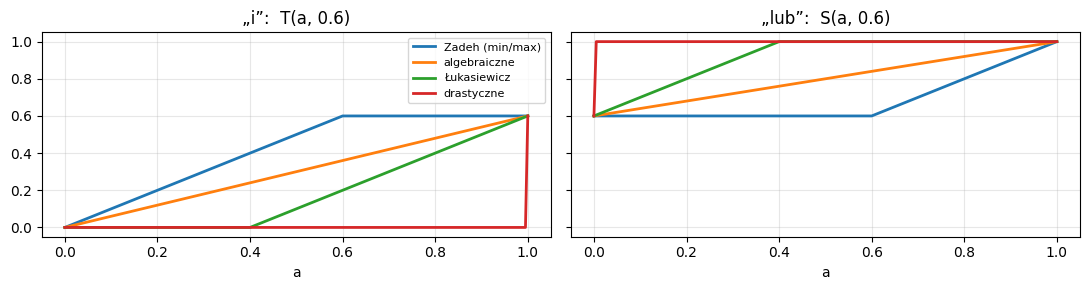

In [12]:
# Wykres kontrolny – porównaj z prezentacją
a_ = np.linspace(0, 1, 201)
b_ = 0.6
fig, osie = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for nazwa, (T, S) in PARY.items():
    osie[0].plot(a_, T(a_, b_), lw=2, label=nazwa)
    osie[1].plot(a_, S(a_, b_), lw=2, label=nazwa)
osie[0].set_title("„i”:  T(a, 0.6)"); osie[1].set_title("„lub”:  S(a, 0.6)")
for o in osie:
    o.set_xlabel("a"); o.grid(alpha=.3)
osie[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### 2.2 Jak wyglądają różne „i”?

Weźmy dwa zbiory: **A = „średnia temperatura”** i **B = „wysoka temperatura”**. Ile prawdy jest w zdaniu „temperatura jest średnia **i** wysoka” – dla każdego operatora?

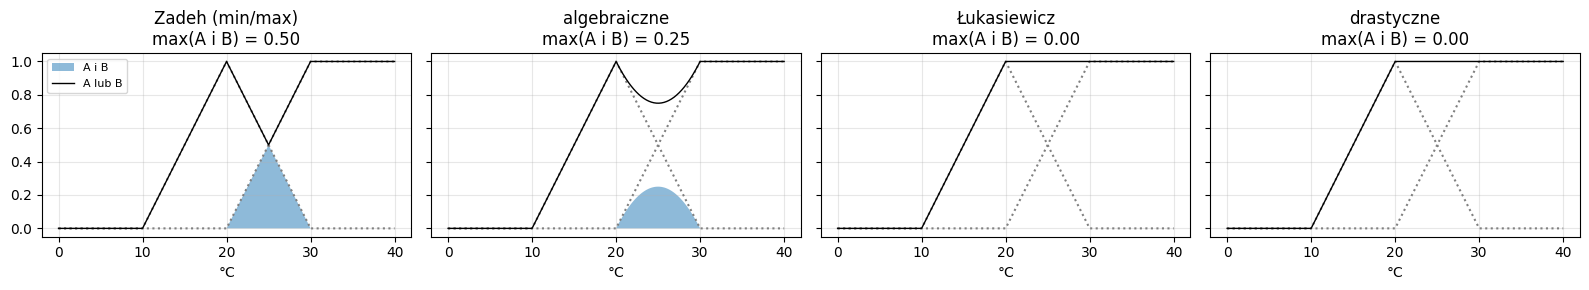

Zadeh (min/max)    S(0.7, 0.7) = 0.70
algebraiczne       S(0.7, 0.7) = 0.91
Łukasiewicz        S(0.7, 0.7) = 1.00
drastyczne         S(0.7, 0.7) = 1.00


In [13]:
x = np.linspace(0, 40, 401)
A_t = t(x, 10, 20, 30)
B_t = gamma(x, 20, 30)

fig, osie = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
for os_, (nazwa, (T, S)) in zip(osie, PARY.items()):
    os_.plot(x, A_t, ":", c="gray"); os_.plot(x, B_t, ":", c="gray")
    os_.fill_between(x, T(A_t, B_t), alpha=.5, label="A i B")
    os_.plot(x, S(A_t, B_t), "k", lw=1, label="A lub B")
    os_.set_title(f"{nazwa}\nmax(A i B) = {np.max(T(A_t, B_t)):.2f}")
    os_.set_xlabel("°C"); os_.grid(alpha=.3)
osie[0].legend(fontsize=8); plt.tight_layout(); plt.show()

# Dwóch niezależnych świadków: każdy jest pewny na 70%, że to był on. „Świadek 1 LUB świadek 2”:
for nazwa, (T, S) in PARY.items():
    print(f"{nazwa:<18} S(0.7, 0.7) = {float(S(0.7, 0.7)):.2f}")

**Pytanie 2a.** Uszereguj cztery „i” od dającego największe wartości do najmniejszych. Przy którym operatorze zdanie „temperatura jest średnia i wysoka” **nigdy** nie jest choć trochę prawdziwe? Czy to rozsądne?

**Pytanie 2b.** Dwóch świadków, każdy pewny na 70%. Ile wynosi „świadek 1 LUB świadek 2” dla każdej pary? Który wynik jest poprawny?

*Twoja odpowiedź:*

**2A:** Po uszeregowaniu wynikiem jest: T_min > T_iloczyn > T_Łukasiewicza > T_drastyczne. Dla zdania "temperatura jest średnia i wysoka" nigdy nie jest prawdziwe z operatorem T_drastyczne, ponieważ zwraca 0 jeśli oba stopnie przynależności są mniejsze od 1. Dla przykładu temperatura może jednocześnie należeć do zbioru "średnia" i "wysoka", a T_drastyczne tego w ogóle nie uwzględnia.

**2B:** Moim zdaniem najbardziej odpowiada S_prob = 0,91 (91%), ponieważ świadkowie w tym przykładnie będą niezależni.Sama odpowiedź jest bardzo bliska wartości 1. Oznacza to prawdopodobieństwo, że przynajmniej jeden świadek ma rację, natomiast 100 % daje nam pewność, która nie jest możliwa do osiągnięcia.

### 2.3 Które prawa logiki przetrwały?

W logice klasycznej (prawda = 1, fałsz = 0) zachodzi pięć praw:

| prawo | zapis | po ludzku |
|---|---|---|
| przemienność | A ∪ B = B ∪ A | kolejność w „lub” nie ma znaczenia |
| idempotentność | A ∩ A = A | „A i A” to po prostu A |
| niesprzeczność | A ∩ ¬A = ∅ | „A i nie-A” jest zawsze fałszem |
| wyłączony środek | A ∪ ¬A = X | „A lub nie-A” jest zawsze prawdą – trzeciej możliwości nie ma |
| de Morgan | ¬(A ∪ B) = ¬A ∩ ¬B | „nie (A lub B)” to „nie A i nie B” |

Czy przetrwają, gdy prawda ma stopnie? Zamiast dowodzić na papierze – sprawdzamy na siatce wszystkich wartości od 0 do 1. Uzupełnij dwa brakujące prawa. Pozostałe są przykładem, jak to zapisać.

In [14]:
siatka = np.linspace(0, 1, 21)
a, b = np.meshgrid(siatka, siatka)       # wszystkie pary (a, b) z siatki

def prawa(T, S):
    return {
        "przemienność A∪B = B∪A":    np.allclose(S(a, b), S(b, a)),
        "idempotentność A∩A = A":    np.allclose(T(a, a), a),
        "niesprzeczność A∩¬A = ∅":   np.allclose(T(a, NIE(a)), 0),
        # TODO: wyłączony środek A∪¬A = X  (X to zbiór, w którym wszystko ma przynależność 1)
        "wyłączony środek A∪¬A = X":  np.allclose(S(a, NIE(a)), 1),
        # TODO: prawo de Morgana ¬(A∪B) = ¬A ∩ ¬B
        "de Morgan ¬(A∪B) = ¬A∩¬B":  np.allclose(NIE(S(a,b)),(T(NIE(a),NIE(b))))
    }

wyniki = {nazwa: prawa(T, S) for nazwa, (T, S) in PARY.items()}
print(f"{'prawo':<28}" + "".join(f"{n.split()[0]:>14}" for n in PARY))
for prawo in next(iter(wyniki.values())):
    print(f"{prawo:<28}" + "".join(f"{'tak' if wyniki[n][prawo] else 'nie':>14}" for n in PARY))

prawo                                Zadeh  algebraiczne   Łukasiewicz    drastyczne
przemienność A∪B = B∪A                 tak           tak           tak           tak
idempotentność A∩A = A                 tak           nie           nie           nie
niesprzeczność A∩¬A = ∅                nie           nie           tak           tak
wyłączony środek A∪¬A = X              nie           nie           tak           tak
de Morgan ¬(A∪B) = ¬A∩¬B               tak           tak           tak           tak


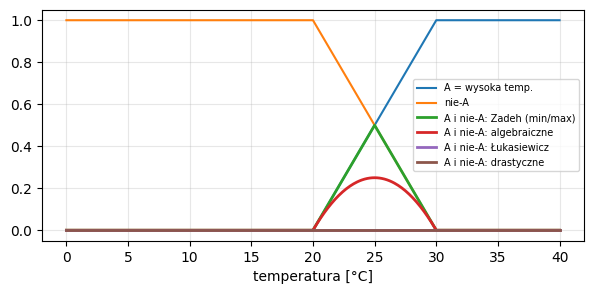

In [15]:
# Jak wygląda „A i nie-A” dla wysokiej temperatury?
A_w = gamma(x, 20, 30)
plt.figure(figsize=(7, 3))
plt.plot(x, A_w, label="A = wysoka temp.")
plt.plot(x, NIE(A_w), label="nie-A")
for nazwa, (T, S) in PARY.items():
    plt.plot(x, T(A_w, NIE(A_w)), lw=2, label=f"A i nie-A: {nazwa}")
plt.xlabel("temperatura [°C]"); plt.legend(fontsize=7); plt.grid(alpha=.3); plt.show()

**Pytanie 2c.** Które prawa logiki klasycznej przetrwały dla każdej pary, a które nie? Czy któraś para zachowuje **wszystkie**?

**Pytanie 2d.** Dla pary Zadeha „A i nie-A” osiąga 0,5 przy 25 °C. To błąd czy zaleta? (Czy o 25 °C da się uczciwie powiedzieć, że jest „trochę gorąco i trochę nie”?)

*Twoja odpowiedź:*

*2c)*  

Wykluczamy dwa prawa logiki klasycznej, które przetrwają dla każdej pary i są to prawa De Morgana i przemienność. Dla reszty wskazanych w zadaniu praw nie wszystkie pary spełniają równanie i pokazane jest to w wyniku zadania. Tylko para 0 i 1 spełniają wszystkie prawa na raz. Inne pary liczb wykluczają się w przynajmniej jednym prawie.

*2d)*  

Biorąc pod uwagę odniesienie do rzeczywistości to jest to zaleta, ponieważ 25 stopni to średnia, która realnie określa "coś pomiędzy" ciepłem a gorącem.

### 2.4 Wybór uczelni – czy operator zmienia decyzję?

Kandydat dostał się na 4 wydziały. Chce, żeby wydział był **wysoko w rankingu I blisko domu I miał dobrą wymianę I dawał dobre szanse na pracę**. Najpierw zamieniamy liczby na stopnie spełnienia kryteriów – Twoimi funkcjami `L` i `gamma`.

In [16]:
wydzialy = {
    #          miejsce w rankingu, odległość [km], uczelnie partnerskie, zatrudnienie [%]
    "w1": (19, 72, 20, 78),
    "w2": (4,  92, 35, 92),
    "w3": (35, 10, 12, 70),
    "w4": (12, 50,  7, 85),
}

def kryteria(ranking, odleglosc, wymiana, praca):
    return [
        L(ranking, 5, 40),        # 'wysoko w rankingu'
        L(odleglosc, 20, 150),    # 'blisko domu'
        gamma(wymiana, 5, 30),    # 'dobra wymiana'
        gamma(praca, 60, 90),     # 'dobre szanse na pracę'
    ]

stopnie = {w: kryteria(*d) for w, d in wydzialy.items()}
print("        ranking  blisko  wymiana  praca")
for w, s in stopnie.items():
    print(w, "  ", "   ".join(f"{float(x):5.2f}" for x in s))

        ranking  blisko  wymiana  praca
w1     0.60    0.60    0.60    0.60
w2     1.00    0.45    1.00    1.00
w3     0.14    1.00    0.28    0.33
w4     0.80    0.77    0.08    0.83


Teraz łączymy cztery kryteria Twoimi t-normami. `reduce(T, [k1, k2, k3, k4])` liczy T(T(T(k1, k2), k3), k4) – czyli „k1 i k2 i k3 i k4”. Dla porównania dodajemy średnią, która **nie** jest t-normą.

In [17]:
operatory = {nazwa: (lambda T: (lambda s: float(reduce(T, s))))(T) for nazwa, (T, S) in PARY.items()}
operatory["średnia (to NIE „i”)"] = lambda s: float(np.mean(s))

print(f"{'operator':<22}" + "".join(f"{w:>7}" for w in wydzialy) + "   ranking")
for nazwa, op in operatory.items():
    oceny = {w: op(s) for w, s in stopnie.items()}
    kolejnosc = " > ".join(sorted(oceny, key=oceny.get, reverse=True))
    print(f"{nazwa:<22}" + "".join(f"{o:7.2f}" for o in oceny.values()) + "   " + kolejnosc)

operator                   w1     w2     w3     w4   ranking
Zadeh (min/max)          0.60   0.45   0.14   0.08   w1 > w2 > w3 > w4
algebraiczne             0.13   0.45   0.01   0.04   w2 > w1 > w4 > w3
Łukasiewicz              0.00   0.45   0.00   0.00   w2 > w1 > w3 > w4
drastyczne               0.00   0.45   0.00   0.00   w2 > w1 > w3 > w4
średnia (to NIE „i”)     0.60   0.86   0.44   0.62   w2 > w4 > w1 > w3


**Pytanie 2e.** Który wydział wygrywa przy minimum, a który przy iloczynie? Spójrz na tabelę stopni i wyjaśnij, **dlaczego** zwycięzca się zmienia.

**Pytanie 2f.** Opisz minimum, iloczyn i Łukasiewicza jednym zdaniem „po ludzku” (np. minimum = „łańcuch jest tak mocny, jak jego najsłabsze ogniwo”). Który z nich najlepiej oddaje to, jak **Ty** wybierałbyś uczelnię?

**Pytanie 2g.** Średnia stawia w4 na drugim miejscu, choć wymiana ma tam ocenę 0,08. Dlaczego średnia to nie jest „i”? Kiedy mimo to byłaby rozsądnym wyborem?

*Twoja odpowiedź:*

*2e)*

Dla minimum wygrywa wydział 1, a dla iloczynu wydział 2. Różnica w wynika z tego, że minimum bierze pod uwagę wyłącznie jedną wadę z wszystkich badanych danych, natomiast iloczyn łączy w wyniku wszystkie wady z badanych danych, dlatego też wynik jest finalnie niższy.

*2f)*

Tak jak opisałam to powyżej - minimum bierze pod uwagę najniższą wartość, a iloczyn sumuje wszystkie wady do wyniku. Dlatego też "łańcuch jest mocny tak, jak jego minimum", ponieważ w minimum nie "mocne" dane nie mają znaczenia, ponieważ wynik jest determinowany głównie przez tą "najniższą" wartość.
W metodzie Łukasiewicza wady się sumują, ale do pewnego momentu. Jak ich wagi przekroczą prób - wynik spada do 0. W tym konkretnym zadaniu najlepszy efekt daje iloczyn, bo on sumuje te wady, a zalety nie mają negatywnego wpływu na wynik. Dlatego też jeżeli porównamy wydziały po iloczynie to wynikiem najwyższym będzie wydział mający najlepsze statystyki.

*2g)*

W średniej wagi wyników mają wpływ na cały wynik, to znaczy, że jeśli wada ma niską wagę, ale jest zaleta z wyższą wagą to wynik jest uśredniany. A wydział 4 ma wysoko ranking i pracę, która zawyża całościowo wynik. Warunek z I narzuca spełnienie wszystkich parametrów na raz, a średnia takiego warunku nie spełnia. Jeżeli ocena miałaby być bezwarunkowa i tylko ogólna - wtedy średnia byłaby dobrym wyborem, ponieważ im więcej zalet by się tam znalazło tym większą i rzetelniejszą ocenę byśmy dostali w uogólnieniu.

---
## Część 3. Sterownik pralki

Wszystko, co do tej pory napisałeś, składa się teraz w **sterownik**: program, który z reguł JEŚLI–TO wylicza jedną liczbę. Pralka ma dwie reguły:

- **R1:** JEŚLI zabrudzenie **duże** I ciężar **średni**, TO czas prania **długi**
- **R2:** JEŚLI zabrudzenie **małe**, TO czas prania **krótki**

Sterownik działa w pięciu krokach:

| krok | co się dzieje | czego używa |
|---|---|---|
| 1. rozmycie | liczby (np. 55%, 4 kg) zamieniamy na stopnie: „duże w stopniu 0,38” | Twoje `L`, `t`, `gamma` |
| 2. siła reguł | ile prawdy jest w części JEŚLI każdej reguły | Twoja t-norma („i”) |
| 3. implikacja | zbiór „długi”/„krótki” przycinamy (min) albo skalujemy (iloczyn) siłą reguły | |
| 4. łączenie | wnioski obu reguł łączymy w jeden kształt | Twoje `S_max` („lub”) |
| 5. wyostrzanie | z kształtu robimy jedną liczbę minut | **piszesz w 3.1** |

### 3.1 Środek ciężkości

Ostatni krok, **wyostrzanie**, zamienia kształt (tablicę stopni `mu` dla każdej wartości `x`) na jedną liczbę. Najczęstsza metoda to **środek ciężkości** (COG) – średnia ważona, w której wagą jest stopień przynależności:

$$x^* = \frac{\sum_i x_i \cdot \mu(x_i)}{\sum_i \mu(x_i)}$$

Zaimplementuj ją. Jeśli wszystkie `mu` są zerami (żadna reguła nie zadziałała), zwróć `np.nan`.

In [22]:
def srodek_ciezkosci(x, mu):
    x, mu = np.asarray(x, float), np.asarray(mu, float)
    # TODO
    suma = mu.sum()

    if suma == 0:
      return np.nan

    return (x * mu).sum()/suma

In [23]:
# Testy
xs = np.array([0.0, 10.0, 20.0, 30.0])
sprawdz("srodek_ciezkosci", srodek_ciezkosci, [((xs, np.array([0, 1, 1, 0])), 15),
                                             ((xs, np.array([0, 0, 0, 1])), 30),
                                             ((xs, np.array([1, 0, 0, 1])), 15),
                                             ((xs, np.array([0, 1, 0, 0.5])), 50 / 3)])

OK    srodek_ciezkosci


### 3.2 Pokręć gałkami

Sterownik jest gotowy – używa Twoich funkcji. Na wykresie: szare kropkowane linie to zbiory „krótki” i „długi”, wypełnienie to wniosek po krokach 2–4, a trzy pionowe linie to trzy metody wyostrzania (Twój środek ciężkości oraz dwie gotowe metody oparte na maksimum).

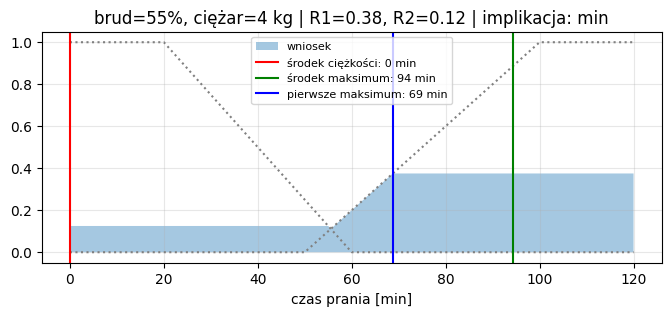

(0.0, np.float64(94.4), np.float64(68.8))

In [20]:
czas = np.linspace(0, 120, 1201)
krotki = L(czas, 20, 60)
dlugi = gamma(czas, 50, 100)

def pralka(brud, ciezar, T=T_min, implikacja="min", pokaz=True):
    # 1. rozmycie wejść
    brud_duzy, brud_maly = gamma(brud, 40, 80), L(brud, 20, 60)
    ciezar_sredni = t(ciezar, 2, 5, 8)
    # 2. siła reguł
    r1 = float(T(brud_duzy, ciezar_sredni))
    r2 = float(brud_maly)
    # 3. implikacja: "min" przycina zbiór, "iloczyn" go skaluje
    if implikacja == "min":
        w1, w2 = np.minimum(r1, dlugi), np.minimum(r2, krotki)
    else:
        w1, w2 = r1 * dlugi, r2 * krotki
    # 4. łączenie wniosków
    wynik = S_max(w1, w2)
    if np.max(wynik) == 0:
        print(f"brud={brud}%, ciężar={ciezar} kg: żadna reguła nie zadziałała!")
        return None
    # 5. wyostrzanie: trzy metody
    cog = srodek_ciezkosci(czas, wynik)
    maks = czas[np.isclose(wynik, np.max(wynik))]
    srodek_maks, pierwsze_maks = maks.mean(), maks.min()
    if pokaz:
        plt.figure(figsize=(8, 3))
        plt.plot(czas, krotki, ":", c="gray"); plt.plot(czas, dlugi, ":", c="gray")
        plt.fill_between(czas, wynik, alpha=.4, label="wniosek")
        for wart, nazwa, kolor in [(cog, "środek ciężkości", "r"), (srodek_maks, "środek maksimum", "g"),
                                   (pierwsze_maks, "pierwsze maksimum", "b")]:
            plt.axvline(wart, c=kolor, label=f"{nazwa}: {wart:.0f} min")
        plt.title(f"brud={brud}%, ciężar={ciezar} kg | R1={r1:.2f}, R2={r2:.2f} | implikacja: {implikacja}")
        plt.xlabel("czas prania [min]"); plt.legend(fontsize=8); plt.grid(alpha=.3); plt.show()
    return round(cog, 1), round(srodek_maks, 1), round(pierwsze_maks, 1)

pralka(brud=55, ciezar=4)

Zmieniaj **po jednej rzeczy** w komórce poniżej i obserwuj wykres:

1. Wejścia: `brud` = 30, 55, 90; `ciezar` = 1, 4, 9.
2. Implikacja: `implikacja="iloczyn"` zamiast `"min"`.
3. Zamiana I na LUB w regule R1: `T=S_max`.

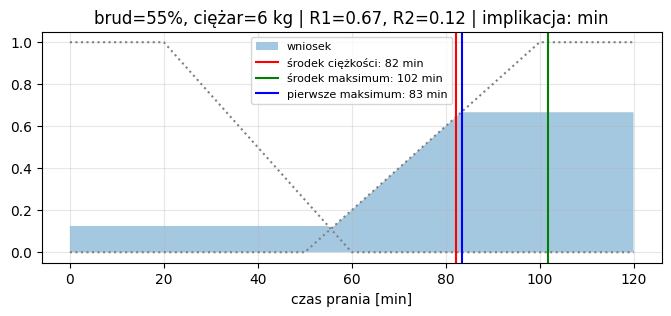

(np.float64(82.1), np.float64(101.7), np.float64(83.4))

In [33]:
# TODO: zmieniaj parametry
pralka(brud=55, ciezar=6, T=S_max, implikacja="min")

**Pytanie 3a.** Co się dzieje dla `brud=90, ciezar=9`? Czy wynik ma sens? Czego brakuje w regułach?

**Pytanie 3b.** Co mocniej przesuwa wynik: zmiana implikacji (min/iloczyn) czy wybór metody wyostrzania (trzy pionowe linie)?

**Pytanie 3c.** Po zamianie I na LUB w regule R1: kiedy pralka pierze długo? Czy tego chciał projektant?

*Twoja odpowiedź:*

*3a)*  

Po uzupełnieniu danych wynika, że mamy wykroczenie poza zakres, ponieważ mamy R2 = 0. Oznacza to, że sterownik nie ma określonej reguły, która uwzględnia co się dzieje jak pranie jest bardzo brudne i bardzo ciężkie. Musiałoby się znaleźć określenie, że pralka musi dłużej pracować.

*3b)*

Wynik zmienia się najbardziej przy zmianie wyostrzania, ponieważ drastycznie zmienia się czas wykonanie. Ale podczas zmiany "min" na "iloczyn" zmienia się w gównej mierze wykres, co nie jest aż tak drastyczne dla czasu realizacji. Gdy zmieniamy środek ciężkości zmienia się tylko lekko kształt całego wykresu.

*3c)*

Różnica między I a LUB jest taka, że stosując w R1 parametr LUB bierzemy pod uwagę którykolwiek z wariantów, czyli albo duży brud albo średni ciężar. W mojej opinii nie ma to sensu, a sam parametr I jest bardziej adekwatny, ponieważ kiedy brud jest duży "i" ciężar jest duży - czas prania ma większe znaczenie. Gdybyśmy mieli duży brud, ale mały ciężar przy wartości LUB wyszłoby nam długi czas prania, co nie byłoby docelowe.